
# Problem 23: Intelligent Grid Navigation Agent using Q-Learning
Bio-Inspired Computing hackathon. A tabular Q-learning agent learns, purely from rewards, to move from Start to Goal on an 8x8 grid with obstacles.


---



## Cell 1: Imports and configuration

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from collections import deque

SEED = 42                    # fixed seed for reproducibility
GRID_SIZE = 8
EPISODES = 2000              # training episodes
ALPHA, GAMMA = 0.1, 0.95     # learning rate, discount factor
EPS_START, EPS_MIN = 1.0, 0.05   # exploration rate (decays during training)
MAX_STEPS = 100              # hard cap per episode -> episodes always terminate
EVAL_EPISODES = 200
print("Setup complete. numpy", np.__version__)

Setup complete. numpy 2.1.3


## Cell 2: Grid environment

In [9]:
ACTION_NAMES = ["Up", "Down", "Left", "Right"]
ACTION_MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # (d_row, d_col)
ACTION_ARROWS = ["^", "v", "<", ">"]

R_GOAL, R_STEP, R_COLLISION = 100.0, -1.0, -10.0     # reward design

class GridWorld:
    """8x8 grid. State = row*size + col. Actions: 0 up, 1 down, 2 left, 3 right.
    Invalid moves (wall or obstacle) leave the agent in place and give R_COLLISION."""
    def __init__(self, size=8, start=(0, 0), goal=(7, 7), obstacles=()):
        self.size, self.start, self.goal = size, tuple(start), tuple(goal)
        self.obstacles = set(map(tuple, obstacles))
        self.n_states, self.n_actions = size * size, 4
        assert self.start not in self.obstacles and self.goal not in self.obstacles
        self.pos = self.start
        # every free cell except the goal can be an (exploring) start cell
        self.free_cells = [(r, c) for r in range(size) for c in range(size)
                           if (r, c) not in self.obstacles and (r, c) != self.goal]

    def to_state(self, pos): return pos[0] * self.size + pos[1]

    def reset(self, start=None):
        self.pos = tuple(start) if start is not None else self.start
        return self.to_state(self.pos)

    def step(self, action):
        dr, dc = ACTION_MOVES[action]
        nr, nc = self.pos[0] + dr, self.pos[1] + dc
        if not (0 <= nr < self.size and 0 <= nc < self.size):
            return self.to_state(self.pos), R_COLLISION, False, "wall"
        if (nr, nc) in self.obstacles:
            return self.to_state(self.pos), R_COLLISION, False, "obstacle"
        self.pos = (nr, nc)
        if self.pos == self.goal:
            return self.to_state(self.pos), R_GOAL, True, "goal"      # terminal
        return self.to_state(self.pos), R_STEP, False, "move"

    def is_solvable(self):
        """VALIDATION ONLY (BFS): is the goal reachable from the start?
        Never used to choose actions or to train the agent."""
        seen, q = {self.start}, deque([self.start])
        while q:
            r, c = q.popleft()
            if (r, c) == self.goal: return True
            for dr, dc in ACTION_MOVES:
                n = (r + dr, c + dc)
                if 0 <= n[0] < self.size and 0 <= n[1] < self.size \
                        and n not in self.obstacles and n not in seen:
                    seen.add(n); q.append(n)
        return False

DEFAULT_OBSTACLES = [(1,1),(1,2),(1,3),(1,5),(2,5),(3,1),(3,3),(3,5),
                     (3,6),(4,3),(5,1),(5,5),(6,3),(6,5),(5,6)]

def make_default_env():
    return GridWorld(GRID_SIZE, (0, 0), (GRID_SIZE-1, GRID_SIZE-1), DEFAULT_OBSTACLES)

env = make_default_env()
print("Default map solvable:", env.is_solvable(), "| obstacles:", len(env.obstacles))

Default map solvable: True | obstacles: 15


## Cell 3: Q-learning agent

In [10]:
class QLearningAgent:
    def __init__(self, n_states, n_actions, alpha=ALPHA, gamma=GAMMA, seed=SEED):
        self.alpha, self.gamma = alpha, gamma
        self.q = np.zeros((n_states, n_actions))      # Q-table
        self.rng = np.random.default_rng(seed)

    def act(self, s, epsilon):
        """Epsilon-greedy with random tie-breaking."""
        if self.rng.random() < epsilon:
            return int(self.rng.integers(self.q.shape[1]))
        best = np.flatnonzero(self.q[s] == self.q[s].max())
        return int(self.rng.choice(best))

    def greedy(self, s):
        return int(np.argmax(self.q[s]))

    def update(self, s, a, r, s_next, done):
        """Q(s,a) <- Q(s,a) + alpha*[r + gamma*max_a' Q(s',a') - Q(s,a)]
        Terminal transitions have no future value (target = r)."""
        target = r if done else r + self.gamma * np.max(self.q[s_next])
        self.q[s, a] += self.alpha * (target - self.q[s, a])

def train(env, agent, episodes=EPISODES, eps_start=EPS_START, eps_min=EPS_MIN,
          max_steps=MAX_STEPS, exploring_start_prob=0.5):
    """Train with epsilon-greedy Q-learning. Epsilon decays exponentially to eps_min
    over the first 70% of episodes. With probability exploring_start_prob an episode
    starts from a random free cell, so values are learned across the whole grid."""
    decay = (eps_min / eps_start) ** (1.0 / max(1, int(0.7 * episodes)))
    eps = eps_start
    hist = {"reward": [], "steps": [], "success": [], "epsilon": []}
    for ep in range(episodes):
        if agent.rng.random() < exploring_start_prob:
            start = env.free_cells[int(agent.rng.integers(len(env.free_cells)))]
        else:
            start = env.start
        s = env.reset(start)
        total, ok, n = 0.0, False, 0
        for n in range(1, max_steps + 1):
            a = agent.act(s, eps)
            s2, r, done, _ = env.step(a)
            agent.update(s, a, r, s2, done)
            total += r; s = s2
            if done: ok = True; break
        hist["reward"].append(total); hist["steps"].append(n)
        hist["success"].append(ok);   hist["epsilon"].append(eps)
        eps = max(eps_min, eps * decay)
    return {k: np.array(v) for k, v in hist.items()}

def greedy_rollout(env, agent, start=None, max_steps=MAX_STEPS):
    """Follow the learned greedy policy (no exploration, no learning)."""
    s = env.reset(start)
    path, total, ok = [env.pos], 0.0, False
    for _ in range(max_steps):
        s, r, done, _ = env.step(agent.greedy(s))
        total += r; path.append(env.pos)
        if done: ok = True; break
    return path, ok, total

def evaluate(env, agent, episodes=EVAL_EPISODES, seed=SEED + 1):
    """Evaluate on SEPARATE episodes (own RNG) with epsilon = 0: starts are random
    free cells. Returns the measured success rate, average path length and reward."""
    rng = np.random.default_rng(seed)
    succ, lens, rews = 0, [], []
    for _ in range(episodes):
        start = env.free_cells[int(rng.integers(len(env.free_cells)))]
        path, ok, total = greedy_rollout(env, agent, start)
        rews.append(total)
        if ok: succ += 1; lens.append(len(path) - 1)
    return {"success_rate": succ / episodes,
            "avg_path_length": float(np.mean(lens)) if lens else float("nan"),
            "avg_reward": float(np.mean(rews)), "episodes": episodes}
print("Q-learning agent defined.")

Q-learning agent defined.


## Cell 4: Train

In [11]:
env = make_default_env()
untrained = QLearningAgent(env.n_states, env.n_actions)        # kept for before/after comparison
agent = QLearningAgent(env.n_states, env.n_actions, seed=SEED)
history = train(env, agent, episodes=EPISODES)
print(f"Trained for {EPISODES} episodes.")
print(f"Mean reward, first 100 episodes: {history['reward'][:100].mean():.1f}")
print(f"Mean reward, last 100 episodes : {history['reward'][-100:].mean():.1f}")
print(f"Training success, last 100 episodes (with exploration): {history['success'][-100:].mean()*100:.0f}%")

Trained for 2000 episodes.
Mean reward, first 100 episodes: -283.7
Mean reward, last 100 episodes : 88.6
Training success, last 100 episodes (with exploration): 100%


## Cell 5: Evaluation and validation tests

In [12]:
# ---- Unit tests ----
e = make_default_env()
e.reset((0, 0)); _, r, d, info = e.step(0)                       # up from top-left = wall
assert (r, d, info, e.pos) == (R_COLLISION, False, "wall", (0, 0))
e.reset((0, 7)); e.step(3); assert e.pos == (0, 7)                # right edge
e.reset((0, 1)); _, r, d, info = e.step(1)                        # (1,1) is an obstacle
assert (r, d, info, e.pos) == (R_COLLISION, False, "obstacle", (0, 1))
e.reset((0, 0)); _, r, d, info = e.step(3)                        # legal move
assert (r, d, info, e.pos) == (R_STEP, False, "move", (0, 1))
e.reset((7, 6)); _, r, d, info = e.step(3)                        # reach goal
assert (r, d, info) == (R_GOAL, True, "goal")
print("PASS: legal/invalid moves, obstacle collision, goal reward + termination")

t = QLearningAgent(64, 4, alpha=0.5, gamma=0.9)
t.q[9] = [0, 2, 1, 0]
t.update(s=0, a=3, r=-1, s_next=9, done=False)                    # 0 + 0.5*(-1 + 0.9*2 - 0)
assert abs(t.q[0, 3] - 0.4) < 1e-9
t.update(s=5, a=1, r=100, s_next=9, done=True)                    # terminal: target = r only
assert abs(t.q[5, 1] - 50.0) < 1e-9
print("PASS: Bellman update (non-terminal and terminal)")

# ---- Evaluate the trained policy (no exploration) ----
res = evaluate(env, agent)
route, route_ok, route_reward = greedy_rollout(env, agent, env.start)
print(f"\nEvaluation over {res['episodes']} separate greedy episodes (random start cells):")
print(f"  Success rate    : {res['success_rate']*100:.1f}%")
print(f"  Avg path length : {res['avg_path_length']:.2f} steps")
print(f"  Avg reward      : {res['avg_reward']:.2f}")
print(f"From the official start {env.start}: reached goal = {route_ok}, "
      f"length = {len(route)-1} steps, reward = {route_reward:.0f}")

assert route_ok and res["success_rate"] > 0.9, "Learning failed - train longer / tune alpha, gamma"
assert all(p not in env.obstacles for p in route), "Route crosses an obstacle!"
assert all(abs(a[0]-b[0]) + abs(a[1]-b[1]) == 1 for a, b in zip(route, route[1:])), "Illegal jump"
assert route[0] == env.start and route[-1] == env.goal
print("PASS: learned route is valid, obstacle-free and ends at the goal")

# Shortest path used ONLY to validate, never to act
def bfs_len(env):
    q, seen = deque([(env.start, 0)]), {env.start}
    while q:
        p, d = q.popleft()
        if p == env.goal: return d
        for dr, dc in ACTION_MOVES:
            n = (p[0]+dr, p[1]+dc)
            if 0 <= n[0] < env.size and 0 <= n[1] < env.size and n not in env.obstacles and n not in seen:
                seen.add(n); q.append((n, d+1))
optimal = bfs_len(env)
print(f"Optimal length (BFS, validation only): {optimal} | learned: {len(route)-1}")

# ---- Failure detection: unreachable goal ----
wall = [(6, 7), (7, 6), (6, 6)]                                   # goal (7,7) sealed off
bad_env = GridWorld(8, (0, 0), (7, 7), wall)
assert not bad_env.is_solvable()
bad_agent = QLearningAgent(bad_env.n_states, 4, seed=SEED)
bad_hist = train(bad_env, bad_agent, episodes=300)
assert bad_hist["success"].sum() == 0 and bad_hist["steps"].max() <= MAX_STEPS
print("PASS: unreachable goal detected (BFS) and agent never succeeds; episodes still terminate")

PASS: legal/invalid moves, obstacle collision, goal reward + termination
PASS: Bellman update (non-terminal and terminal)

Evaluation over 200 separate greedy episodes (random start cells):
  Success rate    : 100.0%
  Avg path length : 7.28 steps
  Avg reward      : 93.72
From the official start (0, 0): reached goal = True, length = 14 steps, reward = 87
PASS: learned route is valid, obstacle-free and ends at the goal
Optimal length (BFS, validation only): 14 | learned: 14
PASS: unreachable goal detected (BFS) and agent never succeeds; episodes still terminate


## Cell 6: Visualization

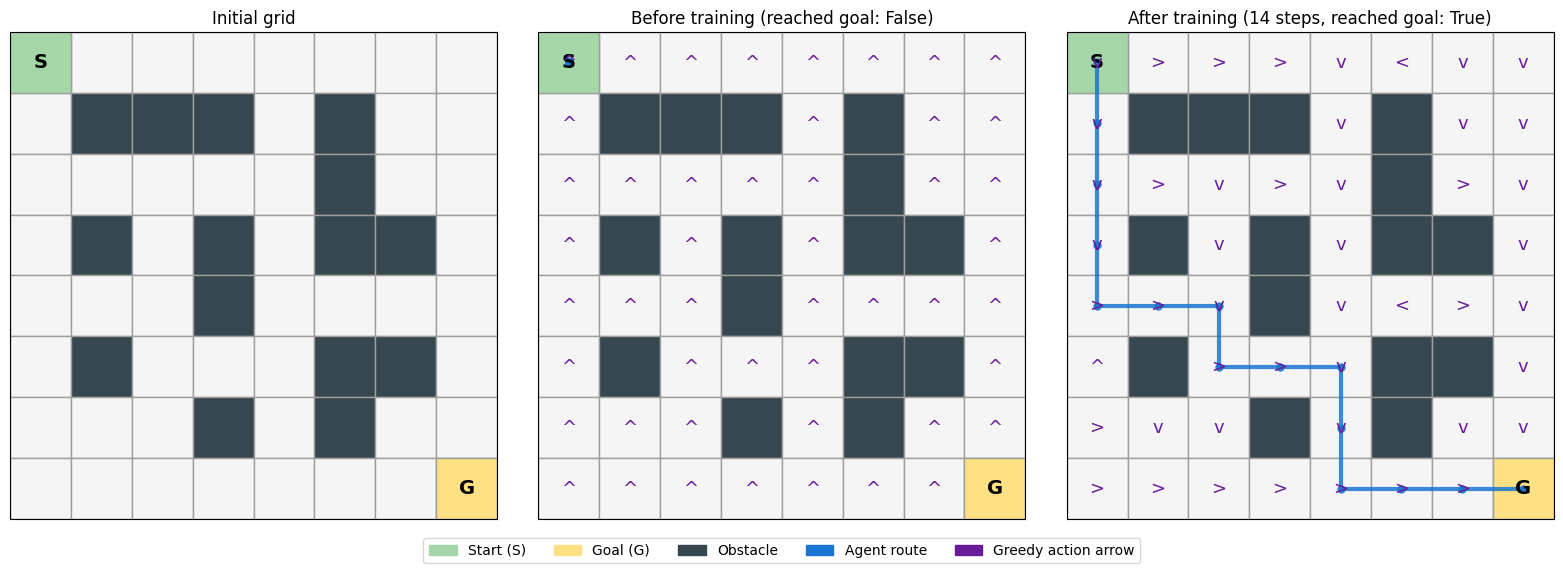

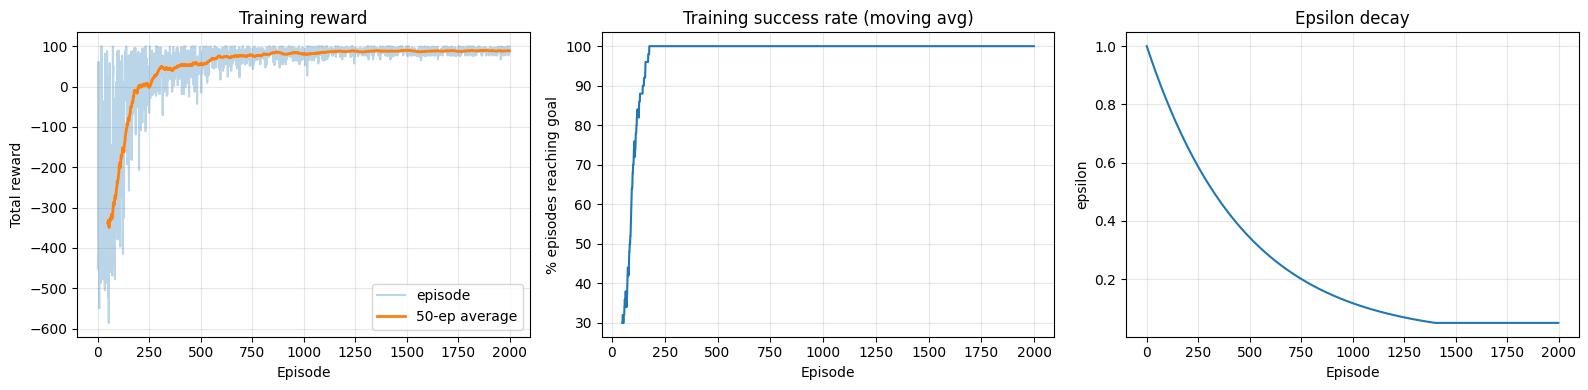

Step-by-step learned route:
  step  1: at (0, 0) -> Down  -> (1, 0)
  step  2: at (1, 0) -> Down  -> (2, 0)
  step  3: at (2, 0) -> Down  -> (3, 0)
  step  4: at (3, 0) -> Down  -> (4, 0)
  step  5: at (4, 0) -> Right -> (4, 1)
  step  6: at (4, 1) -> Right -> (4, 2)
  step  7: at (4, 2) -> Down  -> (5, 2)
  step  8: at (5, 2) -> Right -> (5, 3)
  step  9: at (5, 3) -> Right -> (5, 4)
  step 10: at (5, 4) -> Down  -> (6, 4)
  step 11: at (6, 4) -> Down  -> (7, 4)
  step 12: at (7, 4) -> Right -> (7, 5)
  step 13: at (7, 5) -> Right -> (7, 6)
  step 14: at (7, 6) -> Right -> (7, 7)


In [13]:
def draw_grid(ax, env, agent=None, path=None, title="", show_policy=False):
    n = env.size
    for r in range(n):
        for c in range(n):
            col = "#37474f" if (r, c) in env.obstacles else "#f5f5f5"
            ax.add_patch(Rectangle((c, n-1-r), 1, 1, facecolor=col, edgecolor="#9e9e9e"))
    ax.add_patch(Rectangle((env.start[1], n-1-env.start[0]), 1, 1, facecolor="#a5d6a7", edgecolor="#9e9e9e"))
    ax.add_patch(Rectangle((env.goal[1],  n-1-env.goal[0]),  1, 1, facecolor="#ffe082", edgecolor="#9e9e9e"))
    ax.text(env.start[1]+.5, n-1-env.start[0]+.5, "S", ha="center", va="center", fontsize=14, weight="bold")
    ax.text(env.goal[1]+.5,  n-1-env.goal[0]+.5,  "G", ha="center", va="center", fontsize=14, weight="bold")
    if show_policy and agent is not None:       # greedy action in every free cell
        for (r, c) in env.free_cells:
            a = agent.greedy(env.to_state((r, c)))
            ax.text(c+.5, n-1-r+.5, ACTION_ARROWS[a], ha="center", va="center", fontsize=13, color="#6a1b9a")
    if path is not None and len(path) > 1:
        ax.plot([c+.5 for _, c in path], [n-1-r+.5 for r, _ in path],
                color="#1976d2", lw=3, marker="o", ms=5, alpha=.85)
    ax.set_xlim(0, n); ax.set_ylim(0, n); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)

legend = [Patch(color="#a5d6a7", label="Start (S)"), Patch(color="#ffe082", label="Goal (G)"),
          Patch(color="#37474f", label="Obstacle"), Patch(color="#1976d2", label="Agent route"),
          Patch(color="#6a1b9a", label="Greedy action arrow")]

# 1) Initial grid, before vs after training
b_route, b_ok, _ = greedy_rollout(env, untrained, env.start)
fig, axs = plt.subplots(1, 3, figsize=(16, 5.5))
draw_grid(axs[0], env, title="Initial grid")
draw_grid(axs[1], env, untrained, b_route, f"Before training (reached goal: {b_ok})", show_policy=True)
draw_grid(axs[2], env, agent, route, f"After training ({len(route)-1} steps, reached goal: {route_ok})", show_policy=True)
fig.legend(handles=legend, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

# 2) Training curves
w = 50
ma = lambda x: np.convolve(x, np.ones(w)/w, mode="valid")
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].plot(history["reward"], alpha=.3, label="episode"); axs[0].plot(np.arange(w-1, EPISODES), ma(history["reward"]), lw=2, label=f"{w}-ep average")
axs[0].set(title="Training reward", xlabel="Episode", ylabel="Total reward"); axs[0].legend()
axs[1].plot(np.arange(w-1, EPISODES), ma(history["success"].astype(float))*100)
axs[1].set(title="Training success rate (moving avg)", xlabel="Episode", ylabel="% episodes reaching goal")
axs[2].plot(history["epsilon"]); axs[2].set(title="Epsilon decay", xlabel="Episode", ylabel="epsilon")
for a in axs: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# 3) Step-by-step route table
print("Step-by-step learned route:")
s = env.reset()
for i in range(len(route) - 1):
    a = agent.greedy(env.to_state(route[i]))
    print(f"  step {i+1:2d}: at {route[i]} -> {ACTION_NAMES[a]:5s} -> {route[i+1]}")

## Cell 7: Final results

In [14]:
print("=" * 55)
print("FINAL RESULTS - Q-learning Grid Navigation")
print("=" * 55)
print(f"Grid: {GRID_SIZE}x{GRID_SIZE} | obstacles: {len(env.obstacles)} | seed: {SEED}")
print(f"Hyperparameters: alpha={ALPHA}, gamma={GAMMA}, epsilon {EPS_START} -> {EPS_MIN}")
print(f"Training episodes: {EPISODES}")
print(f"Evaluation episodes (greedy, random starts): {res['episodes']}")
print(f"Success rate: {res['success_rate']*100:.1f}%")
print(f"Average path length: {res['avg_path_length']:.2f} steps")
print(f"Average reward: {res['avg_reward']:.2f}")
print(f"Route from start: {len(route)-1} steps (optimal {optimal}), reward {route_reward:.0f}")

FINAL RESULTS - Q-learning Grid Navigation
Grid: 8x8 | obstacles: 15 | seed: 42
Hyperparameters: alpha=0.1, gamma=0.95, epsilon 1.0 -> 0.05
Training episodes: 2000
Evaluation episodes (greedy, random starts): 200
Success rate: 100.0%
Average path length: 7.28 steps
Average reward: 93.72
Route from start: 14 steps (optimal 14), reward 87
